<a href="https://colab.research.google.com/github/cvoidelo/EPB_omicas_aplicadas_ao_cancer_2026/blob/main/EPB_rna_seq_bulk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução à Análise de Dados Ômicos no Câncer: Transcriptômica - RNA-seq bulk

| Módulo | Conteúdo Principal | Objetivos Didáticos |
|---|---|---|
| **Módulo 0** | O que é o TCGA & Gestão de Dados no GitHub | Entender a origem dos dados públicos e boas práticas de repositório. |
| **Módulo 1** | Setup do Ambiente de Execução (Google Colab / R) | Configuração reprodutível de pacotes do R e Bioconductor. |
| **Módulo 2** | Dados de RNA-Seq (TCGA-CESC) | Construção da matriz de contagens e tabela de metadados (`colData`). |
| **Módulo 3** | Expressão Diferencial com `DESeq2` | Filtros de QC, modelo binomial negativo e normalização. |
| **Módulo 4** | Visualização de DEGs | Representação gráfica (Volcano, Heatmap), correlação e padronização. |
| **Módulo 5** | Enriquecimento Funcional | Análise de processos biológicos (GO) via `clusterProfiler`. |
| **Módulo 6** | Redes Regulatórias com `RTN` | Inferência de TFs e perfis de atividade (*Regulons*). |

---

## Módulo 1: Setup do Ambiente no Google Colab 🔧
Para executar análises de transcriptômica de RNA-Seq no Colab, precisamos instalar o ecossistema do Bioconductor e os pacotes CRAN clássicos de visualização. Execute a célula abaixo para preparar o ambiente.


In [1]:
# Suprimir avisos longos de instalação para manter o notebook limpo
options(warn = -1)

# Instalação do gerenciador do Bioconductor
if (!requireNamespace("BiocManager", quietly = TRUE)) {
    install.packages("BiocManager")
}

# Vetores com as ferramentas analíticas
bioc_packages <- c(
  "DESeq2", "TCGAbiolinks", "SummarizedExperiment",
  "clusterProfiler", "org.Hs.eg.db", "RTN", "apeglm"
)
cran_packages <- c("tidyverse", "pheatmap", "RColorBrewer", "DT")

# Loop de instalação CRAN
for (pkg in cran_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) install.packages(pkg)
}

# Loop de instalação Bioconductor (desativando updates automáticos de dependências)
for (pkg in bioc_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) BiocManager::install(pkg, update = FALSE, ask = FALSE)
}

# Carregamento do ambiente
library(DESeq2)
library(tidyverse)
library(pheatmap)
library(clusterProfiler)
library(org.Hs.eg.db)
library(RTN)
library(TCGAbiolinks)
library(SummarizedExperiment)

cat("✅ Ambiente configurado. Pacotes carregados com sucesso!\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘crosstalk’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'DESeq2'

also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘SummarizedExperiment’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’


'getOption("repos")' replaces Bio

✅ Ambiente configurado. Pacotes carregados com sucesso!


---
## Módulo 2: Download e Estruturação de Dados (TCGA-CESC)
Nesta etapa, utilizamos o pacote `TCGAbiolinks` para baixar dados harmonizados de tumores primários e tecidos normais adjacentes. Para o DESeq2, é mandatório utilizar **contagens brutas (*raw counts*)**, e nunca matrizes já transformadas em TPM ou FPKM.

In [16]:
# 1. Formulação da query no GDC (Genomic Data Commons)
query_geral <- GDCquery(
  project = "TCGA-CESC",
  data.category = "Transcriptome Profiling",
  data.type = "Gene Expression Quantification",
  workflow.type = "STAR - Counts"
)

# Corte de amostras para o Colab ser rápido na aula e não estourar a RAM
# Puxa a lista de amostras, separa todos os normais e apenas 80 tumores
tabela_amostras <- getResults(query_geral)
normais <- tabela_amostras$cases[tabela_amostras$sample_type == "Solid Tissue Normal"]
tumores <- head(tabela_amostras$cases[tabela_amostras$sample_type == "Primary Tumor"], 80)

# Criamos a query final passando as amostras escolhidas direto no 'barcode'
query_cesc <- GDCquery(
  project = "TCGA-CESC",
  data.category = "Transcriptome Profiling",
  data.type = "Gene Expression Quantification",
  workflow.type = "STAR - Counts",
  barcode = c(normais, tumores)
)

# Download rápido
GDCdownload(query_cesc, method = "api")
data_cesc <- GDCprepare(query_cesc)

# 2. Extração da Matriz e Metadados do objeto
counts_matrix <- assay(data_cesc, "unstranded")
col_data <- as.data.frame(colData(data_cesc))


# CONVERSÃO DE ENSEMBL PARA GENE SYMBOL (HGNC)

# O TCGAbiolinks já traz o mapeamento oficial no slot rowData
nomes_genes <- rowData(data_cesc)$gene_name

# Substitui NAs pelo Ensembl original (caso algum gene obscuro não tenha símbolo)
nomes_genes[is.na(nomes_genes)] <- rownames(counts_matrix)[is.na(nomes_genes)]

# Aplica os nomes às linhas da matriz, usando make.unique para evitar duplicatas
rownames(counts_matrix) <- make.unique(nomes_genes)

# 3. Modelagem do Delineamento Experimental
# Identifica tecido normal (NT) e tumoral (TP) na nova coluna 'condition'
col_data$condition <- factor(ifelse(col_data$shortLetterCode == "NT", "Normal", "Tumor"))

# Força o 'Normal' como controle/referência estatística
col_data$condition <- relevel(col_data$condition, ref = "Normal")

# Alinha matriz de contagens aos metadados para evitar erros estruturais depois
counts_matrix <- counts_matrix[, rownames(col_data)]

cat("Dimensões da Matriz de Contagens (Genes x Amostras):", dim(counts_matrix), "\n")

--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-CESC

--------------------

oo Filtering results

--------------------

ooo By data.type

ooo By workflow.type

----------------

oo Checking data

----------------

ooo Checking if there are duplicated cases

ooo Checking if there are results for the query

-------------------

o Preparing output

-------------------

--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-CESC

--------------------

oo Filtering results

--------------------

ooo

|====================================================|100%                      Completed after 5 s 


Starting to add information to samples

 => Add clinical information to samples

 => Adding TCGA molecular information from marker papers

 => Information will have prefix 'paper_' 

cesc subtype information from:doi:10.1038/nature21386

Available assays in SummarizedExperiment : 
  => unstranded
  => stranded_first
  => stranded_second
  => tpm_unstrand
  => fpkm_unstrand
  => fpkm_uq_unstrand



Dimensões da Matriz de Contagens (Genes x Amostras): 60660 83 


---
## Módulo 3 e 4: Expressão Diferencial e Visualização Pós-DESeq2
O modelo DESeq2 engloba a estimativa de *Size Factors* (profundidade de biblioteca), dispersão gene a gene, e a aplicação do teste de Wald. Em seguida, extraímos o `log2FoldChange` e o p-valor ajustado (FDR) para os genes diferenciais.

In [17]:
# 1. Alimentação do Objeto DESeqDataSet
dds <- DESeqDataSetFromMatrix(
  countData = counts_matrix,
  colData = col_data,
  design = ~ condition
)

# 2. Controle de Qualidade: Filtragem de genes de baixa expressão
# Remove genes que não somam pelo menos 10 reads ao longo das amostras
keep <- rowSums(counts(dds) >= 10) >= 3
dds <- dds[keep, ]

# 3. Pipeline Principal (Estimação de dispersão e Modelagem GLM)
dds <- DESeq(dds)

# 4. Encolhimento do Fold Change (LFC Shrinkage via apeglm)
# Melhora o ranking dos genes controlando ruído associado a baixas contagens
res_shrunk <- lfcShrink(dds, coef = "condition_Tumor_vs_Normal", type = "apeglm")

# 5. Organizando a tabela de resultados (DEGs)
df_res <- as.data.frame(res_shrunk) %>%
  rownames_to_column(var = "gene_symbol") %>%
  arrange(padj) %>%
  drop_na(padj) # Remove NAs provenientes da filtragem independente de outliers

# Exibindo os primeiros resultados
head(df_res)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 3270 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895



,gene_symbol,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,TROAP,1965.055,6.168703,0.3549193,7.751085e-71,2.197277e-66
2,CDC6,2950.051,5.462167,0.3451269,2.423094e-59,3.434494e-55
3,KIF2C,3362.179,4.945492,0.3195154,1.748083e-56,1.651822e-52
4,KIF18B,1935.566,6.270847,0.4136046,1.215764e-55,8.616121e-52
5,NEK2,1994.385,6.050393,0.4018050,3.781092e-55,2.143728e-51
6,TOP2A,11885.812,5.660313,0.3901011,2.453173e-50,1.159043e-46


In [38]:
# Arredonda valores numéricos do data.frame de resultados
df_res_print <- df_res
df_res_print[, c("baseMean", "log2FoldChange", "lfcSE", "pvalue", "padj")] <-
  round(df_res_print[, c("baseMean", "log2FoldChange", "lfcSE", "pvalue", "padj")], 4)

# Exibe os top 20 genes
head(df_res_print, 20)

,gene_symbol,baseMean,log2FoldChange,lfcSE,pvalue,padj,Significant
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,TROAP,1965.055,6.1687,0.3549,0,0,Sim
2,CDC6,2950.051,5.4622,0.3451,0,0,Sim
3,KIF2C,3362.179,4.9455,0.3195,0,0,Sim
4,KIF18B,1935.566,6.2708,0.4136,0,0,Sim
5,NEK2,1994.385,6.0504,0.4018,0,0,Sim
6,TOP2A,11885.812,5.6603,0.3901,0,0,Sim
7,DLGAP5,2129.271,6.0358,0.4220,0,0,Sim
8,BUB1,2094.938,4.9710,0.3451,0,0,Sim
9,TPX2,7683.152,5.5813,0.3914,0,0,Sim


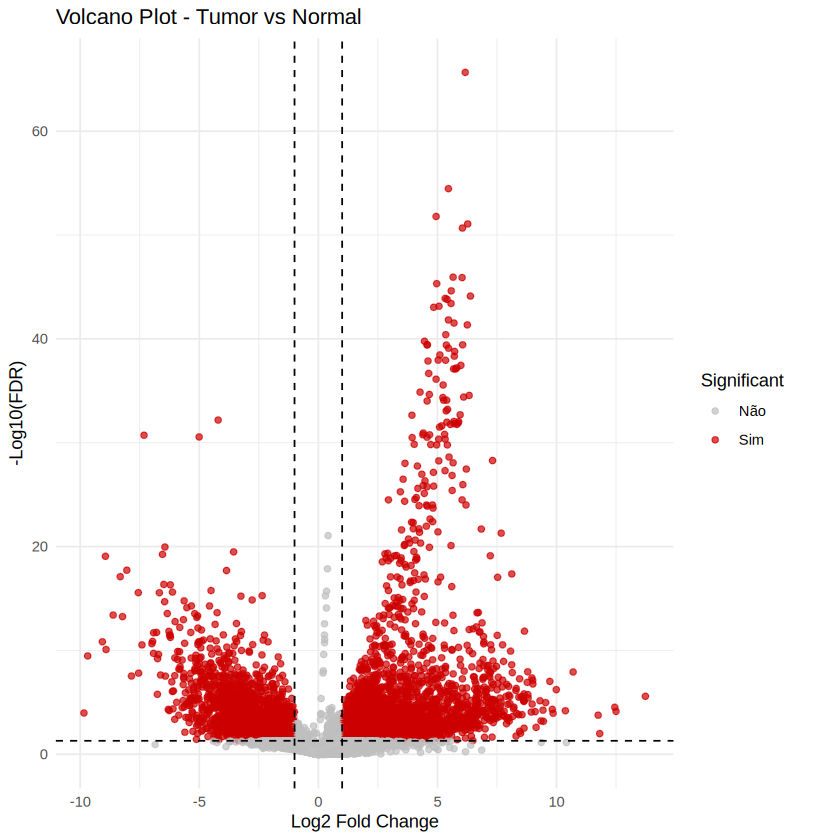

In [54]:
# VISUALIZAÇÃO: Volcano Plot (ggplot2)

# Define o corte de significância: FDR < 0.05 e Log2FC absoluto > 1
df_res <- df_res %>%
  mutate(Significant = factor(ifelse(padj < 0.05 & abs(log2FoldChange) > 1, "Sim", "Não")))

ggplot(df_res, aes(x = log2FoldChange, y = -log10(padj), color = Significant)) +
  geom_point(alpha = 0.7, size = 1.5) +
  scale_color_manual(values = c("gray", "red3")) +
  geom_vline(xintercept = c(-1, 1), linetype = "dashed") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed") +
  theme_minimal() +
  labs(title = "Volcano Plot - Tumor vs Normal", x = "Log2 Fold Change", y = "-Log10(FDR)")


---
### O que o Volcano Plot representa?

O **Volcano Plot** é um gráfico de dispersão que combina a magnitude da alteração de expressão de cada gene com a sua significância estatística, permitindo identificar visualmente os principais alvos biológicos.

* **Eixo X ($\log_2\text{Fold Change}$):** Representa a magnitude e a direção da alteração. Valores positivos (à direita) indicam genes **super-expressos** no tumor (*Up-regulated*), enquanto valores negativos (à esquerda) indicam genes **sub-expressos** (*Down-regulated*).
* **Eixo Y ($-\log_{10}\text{FDR}$):** Representa a significância estatística. Quanto mais alto o ponto no gráfico, menor o p-valor ajustado e maior a confiança de que a alteração observada não ocorreu ao acaso.
* **Linhas de Corte e Cores:** As linhas tracejadas marcam os limites definidos para o experimento ($\text{FDR} < 0.05$ e $|\log_2\text{FC}| > 1$). Os pontos em destaque (vermelhos) cumprem ambos os critérios simultaneamente.

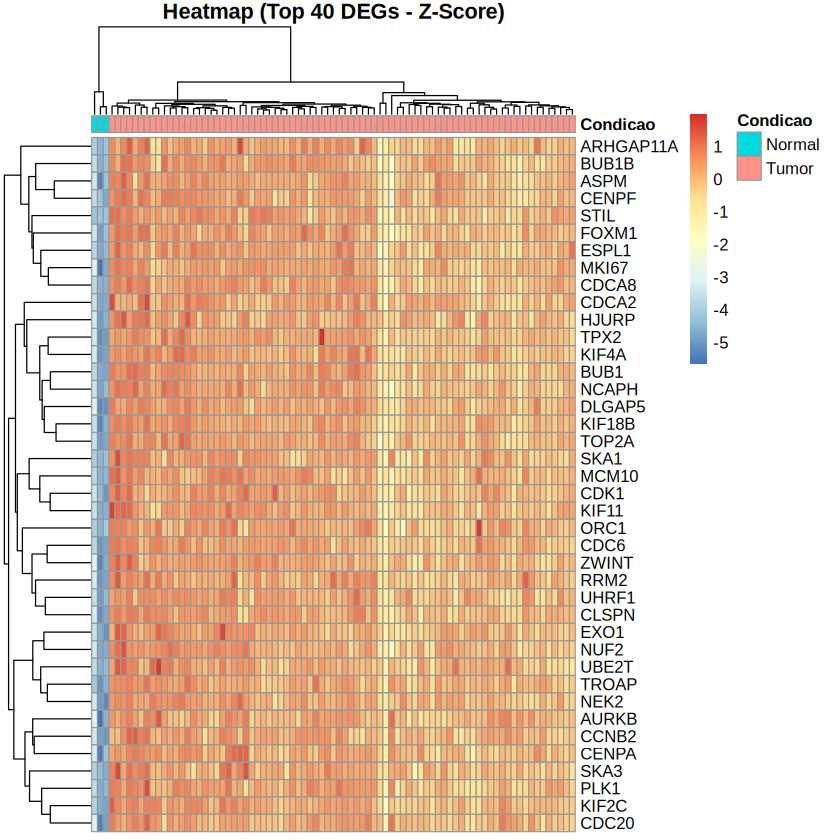

In [55]:
# VISUALIZAÇÃO: Heatmap com Dados Transformados (VST)
vsd <- vst(dds, blind = FALSE)
mat_heatmap <- assay(vsd)[head(df_res$gene_symbol, 40), ] # Top 40 genes
mat_heatmap <- t(scale(t(mat_heatmap))) # Escalonamento Z-score por linha (gene)

annot_df <- data.frame(Condicao = colData(dds)$condition, row.names = colnames(dds))

pheatmap(mat_heatmap, annotation_col = annot_df, show_colnames = FALSE, cluster_cols = TRUE,
         main = "Heatmap (Top 40 DEGs - Z-Score)")

---
### O que o Heatmap de Expressão Genômica representa?

O **Heatmap** exibe o perfil de expressão individual dos genes mais significativos (*Top DEGs*) em todas as amostras analisadas, aplicando a transformação de estabilização de variância (VST) e o escalonamento em **Z-score**.

* **Escala de Cores (Z-Score):** O valor reflete os desvios-padrão em relação à média de expressão de cada gene. Tons quentes (vermelho) indicam expressão **acima da média** naquela amostra, enquanto tons frios (azul) indicam expressão **abaixo da média**.
* **Dendrogramas (Agrupamento Hierárquico):**
  * **Colunas (Amostras):** Agrupam automaticamente os pacientes de acordo com a similaridade do perfil de contagens. Permite verificar se o algoritmo consegue separar espontaneamente o grupo *Tumor* do grupo *Normal*.
  * **Linhas (Genes):** Agrupam genes que compartilham padrões de variação parecidos ao longo das amostras, sugerindo co-regulação funcional.

---
## Correlação Gene-a-Gene (Co-expressão dos Top DEGs)
A análise de correlação entre genes diferencialmente expressos permite identificar módulos de co-expressão transcricional, ajudando a inferir genes que atuam sob os mesmos mecanismos de regulação no tumor.

In [56]:
# Selecionar a matriz de expressão VST para os top 15 DEGs
top_genes <- head(df_res$gene_symbol, 15)
mat_top <- assay(vsd)[top_genes, ]

# Calcular a matriz de correlação de Pearson entre os genes (transpondo a matriz)
cor_mat <- cor(t(mat_top), method = "pearson")

# Tabela dos pares de genes mais correlacionados (sem duplicatas)
df_cor <- as.data.frame(as.table(cor_mat)) %>%
  filter(as.character(Var1) < as.character(Var2)) %>%
  rename(Gene_A = Var1, Gene_B = Var2, Correlação = Freq) %>%
  arrange(desc(abs(Correlação)))

df_cor$Correlação <- round(df_cor$Correlação, 3)

# Exibe os 10 pares com maior correlação no console
head(df_cor, 10)

,Gene_A,Gene_B,Correlação
,<fct>,<fct>,<dbl>
1,KIF18B,TOP2A,0.949
2,CDC20,KIF2C,0.931
3,KIF18B,TPX2,0.931
4,BUB1,DLGAP5,0.927
5,KIF18B,TROAP,0.924
6,CDCA8,MKI67,0.924
7,KIF2C,TROAP,0.921
8,NEK2,TROAP,0.921
9,BUB1,TPX2,0.920


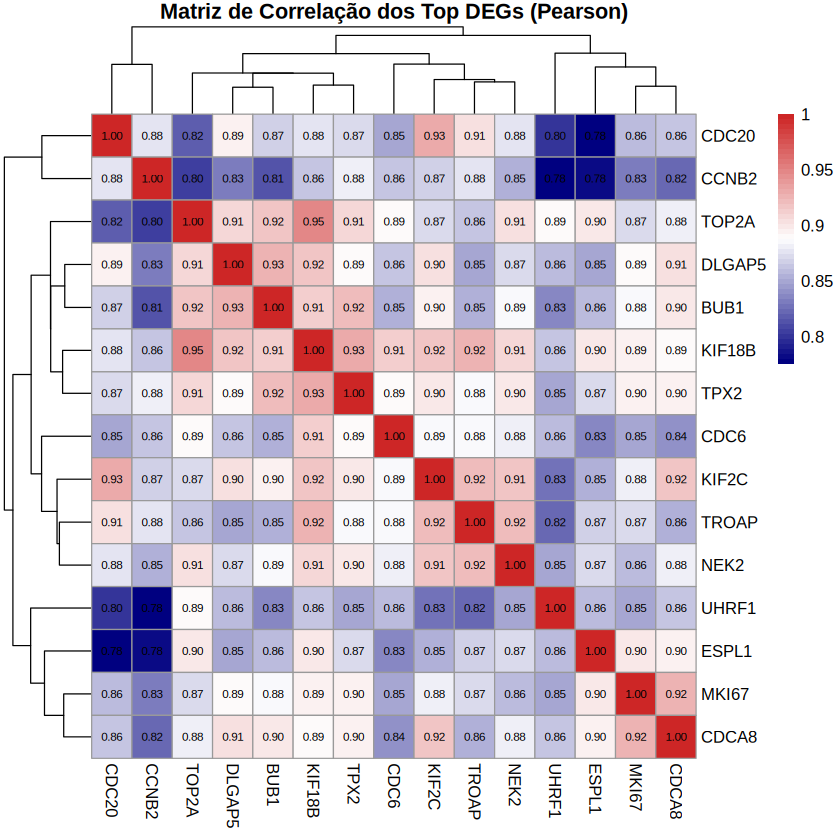

In [57]:
# Plotagem do Heatmap de Correlação Gene-a-Gene
pheatmap(
  cor_mat,
  display_numbers = TRUE,
  number_color = "black",
  fontsize_number = 7,
  color = colorRampPalette(c("navy", "white", "firebrick3"))(50),
  main = "Matriz de Correlação dos Top DEGs (Pearson)"
)

---
### O que o Heatmap de Correlação Gene-a-Gene representa?

O **Heatmap de Correlação de Pearson** avalia o grau de similaridade no comportamento transcricional entre os top genes diferencialmente expressos, permitindo identificar **módulos de co-expressão genômica**.

* **Eixos (Linhas e Colunas):** Contêm a mesma lista de genes de interesse. O ponto de interseção entre uma linha e uma coluna exibe o valor numérico de correlação ($r$) entre aquele par de genes.
* **Diagonal Principal ($r = 1.0$):** Mostra a correlação de um gene com ele mesmo (sempre igual a 1).
* **Escala de Cores:**
  * **Tons Quentes / Vermelho ($r > 0$):** Alta correlação positiva (genes co-expressos).
  * **Tons Frios / Azul ($r < 0$):** Alta correlação negativa (expressão oposta).
  * **Branco ($r \approx 0$):** Ausência de correlação linear significativa.
* **Dendrogramas de Agrupamento:** Reúnem em blocos adjacentes os genes que compartilham perfis de variação idênticos ao longo dos pacientes, revelando módulos funcionais integrados no tumor.

---
## Módulo 5 e 6: Biologia de Sistemas (clusterProfiler e RTN)
O `clusterProfiler` exige a conversão de símbolos HGNC (ex: TP53) para identificadores Entrez ID de banco de dados genômico para realizar o cálculo de enriquecimento hipergeométrico de vias GO.

---
## 5.1: Enriquecimento de vias Biológicas GO
Análise das vias biológicas do Gene Ontology (GO).

'select()' returned 1:1 mapping between keys and columns



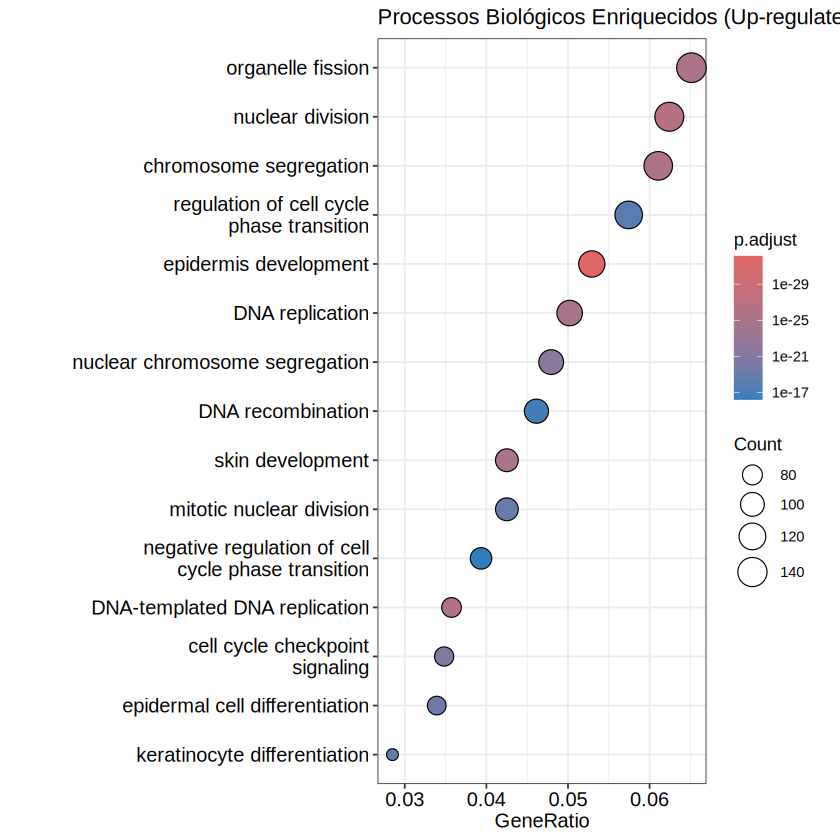

In [29]:
# 1. Selecionando os Genes "Up-regulados" (Super-expressos no Tumor)
# Como a matriz agora usa símbolos oficiais diretamente, extraímos os símbolos diretamente
genes_up <- df_res %>%
  filter(padj < 0.05 & log2FoldChange > 1) %>%
  pull(gene_symbol)

# 2. Conversão de IDs via AnnotationDbi (de SYMBOL para ENTREZID)
entrez_up <- bitr(genes_up, fromType = "SYMBOL", toType = "ENTREZID", OrgDb = org.Hs.eg.db)

# 3. Enriquecimento de Gene Ontology (Biological Processes)
ego_bp <- enrichGO(
  gene          = entrez_up$ENTREZID,
  OrgDb         = org.Hs.eg.db,
  keyType       = "ENTREZID",
  ont           = "BP",
  pAdjustMethod = "BH",
  pvalueCutoff  = 0.05,
  readable      = TRUE # Retorna símbolos HGNC no output ao invés de Entrez numérico
)

# 4. Plotagem do Enriquecimento
dotplot(ego_bp, showCategory = 15, title = "Processos Biológicos Enriquecidos (Up-regulated)")

---
### O que o Gráfico de Enriquecimento GO (Biological Processes) representa?

O **Dotplot de Gene Ontology (GO-BP)** resume os principais processos biológicos coordenados pelos genes diferencialmente expressos (como os genes *Up-regulated* no tumor), permitindo interpretar a funcionalidade celular por trás das alterações de expressão.

* **Eixo Y (Termos de GO):** Lista os processos biológicos ontológicos significativamente enriquecidos na amostra (ex: *cell cycle*, *DNA repair*, *extracellular matrix organization*).
* **Eixo X (GeneRatio):** Representa a proporção entre o número de genes da sua lista mapeados na via e o total de genes da lista que possuem anotação de GO. Quanto maior o valor, maior a representatividade daquela via.
* **Tamanho dos Pontos (Count):** Indica a quantidade absoluta de genes da sua lista que pertencem a determinado processo biológico.
* **Escala de Cores (`p.adjust` / FDR):** Reflete a significância estatística do teste hipergeométrico. Tons mais **vermelhos** indicam p-valores ajustados mais baixos (menor FDR), confirmando alta confiança estatística de que o enriquecimento da via não ocorreu ao acaso.

---
## 5.2: Enriquecimento de Hallmarks do Câncer (MSigDB)
Além das vias biológicas do Gene Ontology (GO), a análise de *Hallmarks* do câncer fornece uma visão funcional direcionada à oncologia. Utilizaremos o pacote `msigdbr` para acessar o banco de dados do MSigDB diretamente no R.

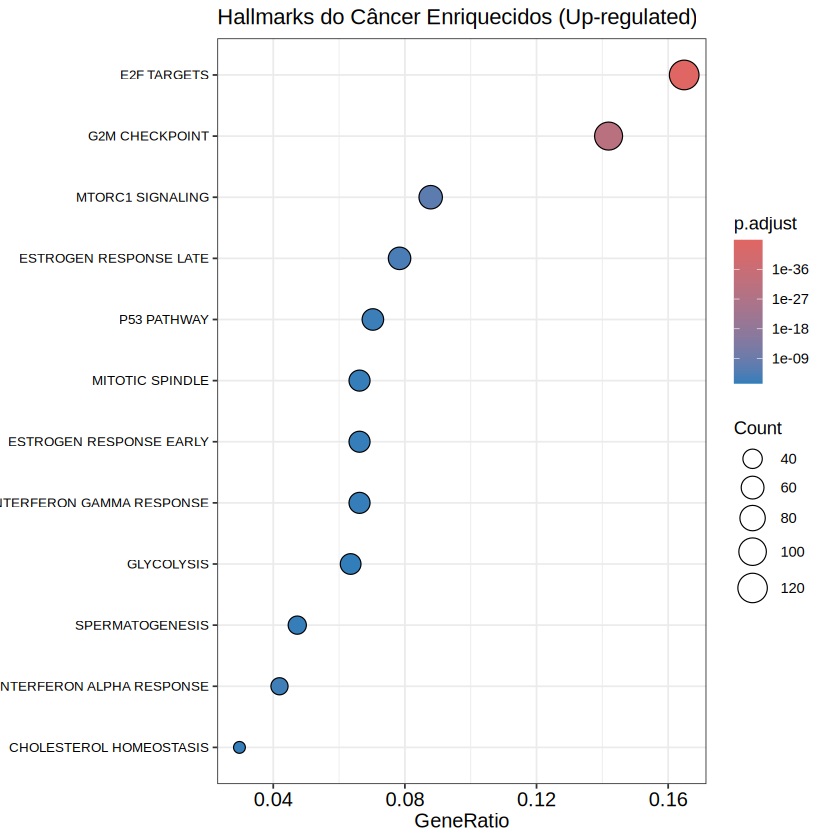

In [30]:
# ==============================================================================
# ENRIQUECIMENTO DE HALLMARKS ONCOGÊNICOS (MSigDB)
# ==============================================================================
# Instalação rápida do msigdbr caso não tenha sido incluído no setup inicial
if (!requireNamespace("msigdbr", quietly = TRUE)) install.packages("msigdbr")
library(msigdbr)

# 1. Carregar a coleção de Hallmarks (Categoria "H" para Homo sapiens)
m_t2g <- msigdbr(species = "Homo sapiens", category = "H") %>%
  dplyr::select(gs_name, entrez_gene)

# 2. Teste de Enriquecimento Hipergeométrico para os Hallmarks
# Utilizamos a mesma lista de genes Up-regulados (entrez_up) calculada na célula anterior
em_hallmarks <- enricher(
  gene = entrez_up$ENTREZID,
  TERM2GENE = m_t2g,
  pAdjustMethod = "BH",
  pvalueCutoff = 0.05
)

# 3. Limpeza dos nomes das vias para melhorar o visual do gráfico
# Remove o prefixo "HALLMARK_" para ficar esteticamente agradável no plot
em_hallmarks@result$ID <- gsub("HALLMARK_", "", em_hallmarks@result$ID)
em_hallmarks@result$Description <- gsub("HALLMARK_", "", em_hallmarks@result$Description)

# 4. Plotagem dos Hallmarks Enriquecidos
dotplot(em_hallmarks, showCategory = 15, title = "Hallmarks do Câncer Enriquecidos (Up-regulated)") +
  theme(axis.text.y = element_text(size = 8)) # Ajusta o tamanho da fonte

---
### O que o Gráfico de Enriquecimento de Hallmarks representa?

O **Dotplot de Hallmarks do Câncer (MSigDB)** avalia a interpretação funcional sob a perspectiva da oncologia integrativa, identificando se os genes diferencialmente expressos se concentram em assinaturas moleculares consolidadas da progressão tumoral.

* **Eixo Y (Assinaturas Oncogênicas):** Lista os programas biológicos do MSigDB (*Hallmark Gene Sets*) significativamente enriquecidos (ex: *E2F Targets*, *G2M Checkpoint*, *Epithelial Mesenchymal Transition*).
* **Eixo X (GeneRatio):** Proporção entre os genes da sua lista inseridos na assinatura e o total de genes anotados para aquele *Hallmark*.
* **Tamanho dos Pontos (Count):** Quantidade de genes da sua lista mapeados no programa biológico.
* **Escala de Cores (`p.adjust` / FDR):** Significância estatística do teste hipergeométrico. Cores mais **vermelhas** indicam menor valor de FDR (maior confiança estatística).

---

### Qual a diferença entre a análise de GO (Biological Processes) e Hallmarks?

| Aspecto | Gene Ontology (GO-BP) | MSigDB Hallmarks |
|---|---|---|
| **Escopo e Resolução** | Detalha mecanismos celulares específicos e hierárquicos (milhares de termos como *mitotic spindle assembly* ou *collagen catabolic process*). | Agrupa o comportamento tumoral em estados macro e integrados (apenas 50 assinaturas consolidadas). |
| **Redundância de Termos** | **Alta**: gera muitos termos sobrepostos com nomes parecidos para o mesmo evento biológico. | **Baixa**: vias desenhadas para minimizar overlapping de genes e facilitar a síntese didática. |
| **Aplicação Principal** | Descobrir a função biológica detalhada e o mecanismo de ação refinado dos genes. | Mapear o perfil oncogênico global e os fenótipos tumorais predominantes na coorte. |

---
## Módulo 6: Inferência de Redes Regulatórias (RTN)
O pacote `RTN` reconstrói redes de regulação transcricional usando Informação Mútua e o algoritmo ARACNe para remover interações indiretas. Aqui, vamos inferir os *regulons* (um Fator de Transcrição + seus genes alvo) e calcular a atividade deles nas amostras de tumor vs. normal.

In [59]:
# ==============================================================================
# INFERÊNCIA DE REDES REGULATÓRIAS COM RTN
# ==============================================================================
library(RTN)

# Preparação dos dados: Matriz de expressão VST e Fatores de Transcrição (TFs)
exp_matrix <- assay(vsd)

# Lista de TFs oncogênicos clássicos como exemplo para a aula
tfs_symbols <- c("E2F1", "FOXM1", "TP53", "MYC", "ESR1")

# Como a matriz agora usa símbolos oficiais diretamente como rownames, a busca é direta
tfs_presentes <- intersect(tfs_symbols, rownames(exp_matrix))

# Inicialização do objeto TNI (Transcriptional Network Inference)
rtni <- tni.constructor(
  expData = exp_matrix,
  regulatoryElements = tfs_presentes
)

# 3. Cálculo da Informação Mútua e Permutação
# [NOTA P/ AULA] Reduzimos nPermutations para 100 para rodar rápido no Colab. Em artigos, use 1000.
rtni <- tni.permutation(rtni, nPermutations = 100)

# Bootstrap e Filtro DPI (ARACNe) para remover redundâncias e manter interações diretas
rtni <- tni.bootstrap(rtni)
rtni <- tni.dpi.filter(rtni)

# Análise de Atividade (GSEA-2T)
# Reduzimos o 'minRegulonSize' para 1 devido à restrição do tamanho da nossa matriz amostral na aula
rtni <- tni.gsea2(rtni, minRegulonSize = 1)

# Extração dos resultados de atividade (Regulon Activity Profile - RAP)
reg_act <- tni.get(rtni, what = "regulonActivity")

# Matriz com a atividade dos Regulons (dif)
mat_activity <- t(reg_act$dif)

-Preprocessing for input data...
--Checking 'regulatoryElements' in 'rowAnnotation'...
--Checking 'expData'...
-Preprocessing complete!

-Performing permutation analysis...
--For 5 regulons...
  |======================================================================| 100%
-Permutation analysis complete! 

-Performing bootstrap analysis...
--For 5 regulons...
  |======================================================================| 100%
-Bootstrap analysis complete! 

-Applying dpi filter...
-DPI filter complete! 

-Checking log space... OK!
-Performing two-tailed GSEA...
--For 5 regulon(s) and 83 sample(s)...
  |======================================================================| 100%
-GSEA2 complete! 



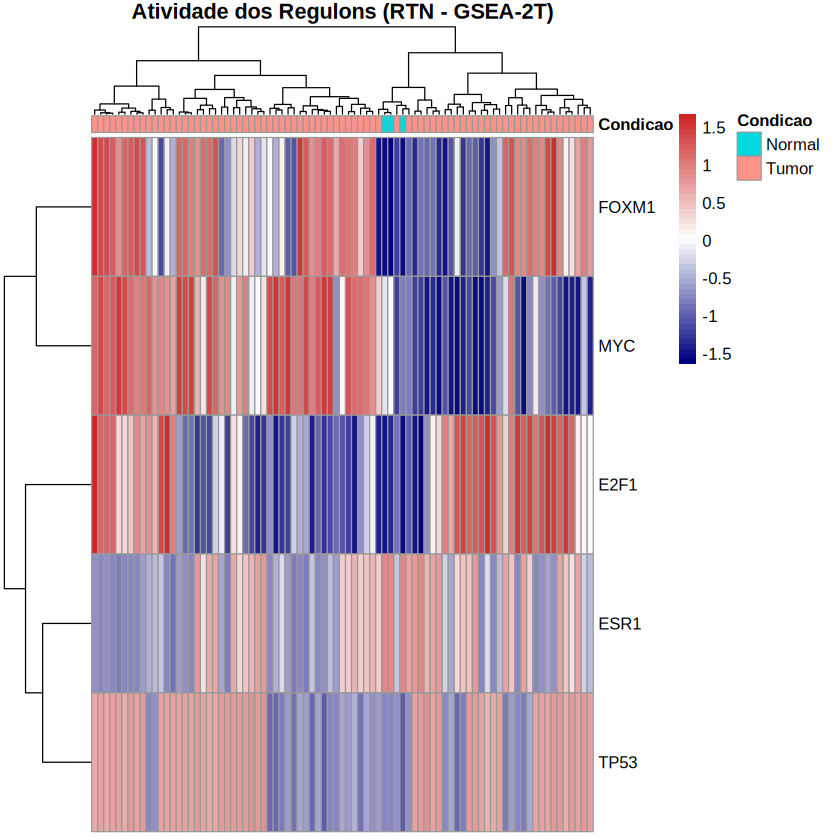

In [58]:
# Visualização da Atividade dos Regulons
# Evita erro de clustering hierárquico caso haja apenas 1 regulon ativo no resultado
deve_agrupar_linhas <- nrow(mat_activity) >= 2

pheatmap(
  mat_activity,
  annotation_col = annot_df, # Usando a mesma anotação do Módulo 4
  show_colnames = FALSE,
  cluster_rows = deve_agrupar_linhas,
  cluster_cols = TRUE,
  clustering_method = "ward.D2",
  main = "Atividade dos Regulons (RTN - GSEA-2T)",
  color = colorRampPalette(c("navy", "white", "firebrick3"))(50)
)

---
### O que o Heatmap de Atividade dos Regulons (RTN) representa?

O heatmap exibe o **Perfil de Atividade dos Regulons (RAP)** inferido pelo algoritmo **RTN** via GSEA de duas caudas (GSEA-2T). Um *regulon* é a unidade funcional formada por um Fator de Transcrição (TF) e todos os seus genes alvo (*targets*) inferidos pela rede.

* **Escores de Atividade (Cores):**
  * **Vermelho (Escore Positivo):** Regulon **superativado** na amostra (a expressão dos seus genes alvo está predominantemente aumentada).
  * **Azul (Escore Negativo):** Regulon **reprimido** na amostra (seus genes alvo estão predominantemente sub-expressos).
* **Agrupamento de Amostras (Colunas):** Revela se o estado de ativação das redes regulatórias é suficiente para separar espontaneamente o tecido tumoral do tecido normal.
* **Agrupamento de Regulons (Linhas):** Identifica TFs que atuam em sintonia ou possuem perfis opostos durante a oncogênese.

---
### O que o Heatmap de Atividade dos Regulons representa?

O heatmap exibe o **Perfil de Atividade dos Regulons (RAP)** calculado via GSEA de duas caudas (GSEA-2T). Um *regulon* é o conjunto formado por um Fator de Transcrição (TF) e todos os seus genes alvo inferidos pela rede.

* **Vermelho (Escore Positivo):** Indica **superativação** do regulon na amostra (seus genes alvo estão predominantemente expressos).
* **Azul (Escore Negativo):** Indica **repressão** do regulon (seus genes alvo estão predominantemente sub-expressos).
* **Padrão de Agrupamento:** Permite identificar se a ativação de regulons específicos diferencia o tecido tumoral do tecido normal adjacente.

In [35]:
# 1. Extração dos regulons e contagem do número de genes alvo por TF
regulons_list <- tni.get(rtni, what = "regulons")

# 2. Construção do data.frame com a atividade média por grupo
df_reg_summary <- data.frame(
  Fator_Transcricao = names(regulons_list),
  Total_Alvos = sapply(regulons_list, length),
  Atividade_Media_Normal = round(rowMeans(mat_activity[, annot_df$Condicao == "Normal", drop = FALSE]), 3),
  Atividade_Media_Tumor = round(rowMeans(mat_activity[, annot_df$Condicao == "Tumor", drop = FALSE]), 3)
)

# 3. Exibição limpa via console padrão
head(df_reg_summary)

,Fator_Transcricao,Total_Alvos,Atividade_Media_Normal,Atividade_Media_Tumor
,<chr>,<int>,<dbl>,<dbl>
E2F1,E2F1,15,-1.443,0.062
ESR1,ESR1,25,0.901,-0.090
FOXM1,FOXM1,82,-1.565,0.272
MYC,MYC,73,-0.283,0.159
TP53,TP53,1,-0.810,0.154


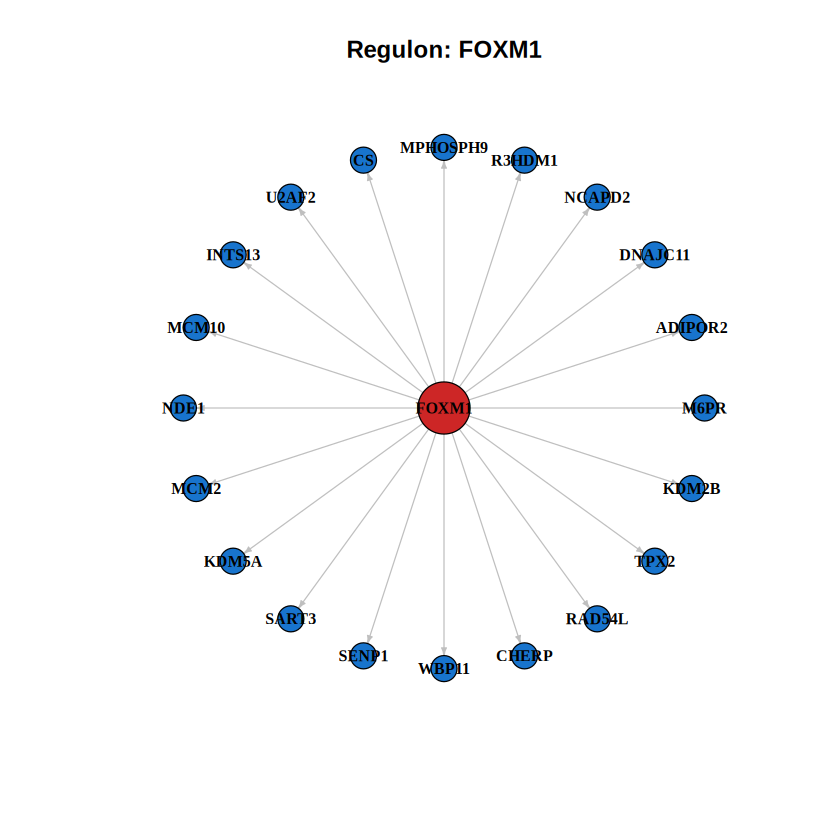

In [53]:
library(igraph)

# 1. Definir o TF e extrair os 20 primeiros alvos do regulon
tf <- "FOXM1" #Mudar aqui para MYC, TP53, ESR1, etc.
alvos <- head(tni.get(rtni, what = "regulons")[[tf]], 20)

# 2. Criar o grafo do regulon
g <- graph_from_data_frame(data.frame(TF = tf, Target = alvos), directed = TRUE)

# 3. Plotar a rede em layout de estrela (TF no centro)
set.seed(42)
plot(
  g,
  layout = layout_as_star(g, center = tf),
  vertex.color = ifelse(V(g)$name == tf, "firebrick3", "dodgerblue3"),
  vertex.size = ifelse(V(g)$name == tf, 20, 10),
  vertex.label.color = "black",
  vertex.label.cex = 0.8,
  vertex.label.font = 2,
  edge.arrow.size = 0.3,
  edge.color = "gray75",
  main = paste("Regulon:", tf)
)

---
### O que a Rede Regulatória (Grafo do Regulon) representa?

O **Grafo da Rede Regulatória** visualiza a topologia de conexões entre um Fator de Transcrição (TF) e seus genes alvo (*targets*) inferidos estatisticamente via informação mútua e filtrados pelo algoritmo ARACNe (DPI).

* **Nó Central / Hub (Vermelho):** Representa o **Fator de Transcrição (TF)** principal (ex: *FOXM1*). Ele atua como o regulador mestre responsável por orquestrar a expressão do módulo.
* **Nós Periféricos (Azul):** Representam os **genes alvo (*targets*)** que compõem o regulon daquele TF no contexto biológico analisado.
* **Arestas / Conexões (Linhas):** Representam as interações regulatórias diretas inferidas entre o TF e os genes.
* **Layout em Estrela:** Posiciona o regulador no centro geométrico da rede, facilitando a identificação individual de cada gene dependente e a avaliação da amplitude do regulon.

---
## FINALIZAÇÃO: Exportação de Resultados no Google Drive 💾

### Por que montar o Google Drive e salvar os resultados lá?

1. **Persistência:** As instâncias do Google Colab são temporárias. Quando a sessão desconecta (seja por tempo limite, inatividade ou fechamento da aba), todo o sistema de arquivos local da máquina virtual (`/content/`) é apagado permanentemente.
2. **Centralização de Outputs:** Ao montar o Google Drive, o caminho `/content/drive/MyDrive/` passa a funcionar como um diretório local do R. Isso permite salvar figuras em alta resolução (`.png`, `.pdf`), tabelas (`.csv`) e os próprios objetos do R (`.rds`) diretamente na sua nuvem.
3. **Economia de Tempo e Reprodutibilidade:** Salvar o objeto compilado do `DESeq2` (`.rds`) evita a necessidade de re-executar etapas demoradas de download e estimativa de dispersão em análises futuras.

In [ ]:
# 1. Monta o Google Drive no ambiente R do Colab
system("python3 -c 'from google.colab import drive; drive.mount(\"/content/drive\")'")

# 2. Cria a pasta de destino dentro do seu Google Drive
dir_saida <- "/content/drive/MyDrive/Curso_Transcriptomica_TCGA"
dir.create(dir_saida, showWarnings = FALSE, recursive = TRUE)

# 3. Exporta a tabela de DEGs em formato CSV
write.csv(df_res, file = file.path(dir_saida, "DEGs_TCGA_CESC.csv"), row.names = FALSE)

# 4. Salva o objeto dds processado (RDS) para reaproveitamento futuro
saveRDS(dds, file = file.path(dir_saida, "objeto_dds_cesc.rds"))

# 5. Salva a última figura gerada (ex: Volcano Plot) em alta resolução (300 DPI)
ggplot2::ggsave(
  filename = file.path(dir_saida, "Volcano_Plot_TCGA.png"),
  plot = ggplot2::last_plot(),
  dpi = 300, width = 7, height = 5
)

cat("✅ Arquivos salvos com sucesso na pasta do Google Drive:\n", dir_saida, "\n")

---
## Referências e Boas Práticas

##DSeq2:
Referência: LOVE, M. I.; HUBER, W.; ANDERS, S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. **Genome Biology**, Londres, v. 15, n. 12, p. 550, dez. 2014. DOI: 10.1186/s13059-014-0550-8.
Vignette: https://bioconductor.org/packages/devel/bioc/vignettes/DESeq2/inst/doc/DESeq2.html

##ClusterProfiler:
Referência: WU, T. *et al*. clusterProfiler 4.0: A universal enrichment tool for interpreting omics data. **The Innovation**, Pequim, v. 2, n. 3, p. 100141, ago. 2021. DOI: 10.1016/j.xinn.2021.100141.
Vignette: https://bioconductor.org/packages/devel/bioc/vignettes/clusterProfiler/inst/doc/clusterProfiler.html

##RTN:
Referência: CASTRO, M. A. A. *et al*. Regulators of genetic risk of breast cancer identified by integrative network analysis. **Nature Genetics**, Nova York, v. 48, n. 1, p. 12-21, jan. 2016. DOI: 10.1038/ng.3458.
Vignette: https://bioconductor.org/packages/release/bioc/vignettes/RTN/inst/doc/RTN.html